# K-Drama AI - Project 2: Unsupervised Learning
## Hidden patterns of K-Dramas: groups, low-dimensional structure and unusual dramas

**Course:** AI Fundamentals - Final Project (Unsupervised Learning worksheet) &nbsp;|&nbsp; **Variant 21 - Movie preference**, adapted to Korean dramas

**Team (QAIRU): Shakenova Aruzhan, Qabir Madina, Shahap Aizere, Zholdaspek Dana**

| Item | Our choice |
|---|---|
| Object | Korean TV dramas listed on MyDramaList (2015-2023) |
| Observation unit | one drama (one row = one drama) |
| Research question | Do K-Dramas form natural groups by genre score, runtime and popularity? Is there a simple low-dimensional structure? Which dramas are unusual? |
| Variant features | `genre_score`, `runtime_min`, `popularity` |
| Extra features | `episodes`, `public_rating` |
| Label | **none** - the "liked" target of Project 1 is not loaded and not used anywhere in this notebook |

Methods: K-Means, DBSCAN, PCA, t-SNE, UMAP and Isolation Forest. All figures and numbers are produced by the code below.

## Step 1 - Install and import the libraries

Google Colab already has NumPy, pandas, Matplotlib and scikit-learn. UMAP lives in the package `umap-learn`
(it is imported as `umap`), so we install it only if it is missing.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score

try:
    import umap
except ImportError:
    %pip -q install umap-learn
    import umap

SEED = 42
pd.set_option("display.width", 170)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
PALETTE = ["#c97b8e", "#9d8cc9", "#e0b973", "#5fa8a3", "#d98f5c", "#6f86c9", "#7a1f3d", "#b8b8c4"]
print("Libraries are ready.")

Libraries are ready.


## Step 2 - Download the real data and inspect X

**Sources (both scraped from MyDramaList.com and published on Kaggle):**

* **Source A** - Chanon Charuchinda (2023). *Korean Drama from 2015-2023 with Actors & Reviews*. Kaggle, CC0 Public Domain.
  <https://www.kaggle.com/datasets/chanoncharuchinda/korean-drama-2015-23-actor-and-reviewmydramalist> - runtime, episodes, popularity rank.
* **Source B** - Noor Rizki (2023). *Top Korean Drama List (~1500)*. Kaggle, licence not stated.
  <https://www.kaggle.com/datasets/noorrizki/top-korean-drama-list-1500> - genres and public rating.

The loader is the same code that Project 1 uses. It returns two tables; **this project uses only the `dramas` table**.
The `reviews` table (which contains the Project 1 target) is deleted immediately so it cannot be used by mistake.

**Drama-level `genre_score`.** First we compute the average public rating of every genre. Then, for each drama, we average
these values over the drama's genres. It answers: "how well-rated are this drama's genres in general?". No viewer label is involved.

In [2]:
"""K-Drama AI - data loading and feature engineering.

This single file builds BOTH tables used in the project:

* the DRAMA table   (one row = one K-Drama)            -> Project 2, website catalogue
* the REVIEW table  (one row = one viewer x one drama) -> Project 1

Everything comes from two public Kaggle datasets that were scraped from
MyDramaList (MDL). Nothing in these tables is simulated.

Source A  Chanon Charuchinda (2023), "Korean Drama from 2015-2023 with Actors & Reviews",
          Kaggle, licence CC0: Public Domain.
          https://www.kaggle.com/datasets/chanoncharuchinda/korean-drama-2015-23-actor-and-reviewmydramalist
          files used: korean_drama.csv (1,752 dramas), reviews.csv (10,625 viewer reviews)

Source B  Noor Rizki (2023), "Top Korean Drama List (~1500)", Kaggle, licence not stated ("Unknown").
          https://www.kaggle.com/datasets/noorrizki/top-korean-drama-list-1500
          file used: kdrama_list.csv (1,647 dramas with genres and the public MDL score)
"""

import io
import re
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd

KAGGLE_DOWNLOAD = "https://www.kaggle.com/api/v1/datasets/download/"
SOURCE_A = "chanoncharuchinda/korean-drama-2015-23-actor-and-reviewmydramalist"
SOURCE_B = "noorrizki/top-korean-drama-list-1500"
RAW_FILES = {
    "korean_drama.csv": SOURCE_A,
    "reviews.csv": SOURCE_A,
    "kdrama_list.csv": SOURCE_B,
}

LIKE_THRESHOLD = 8.0          # a viewer "likes" a drama when their own overall score is >= 8 / 10
MISSING_RANK_CODE = 99999     # Source A writes 99999 when MDL shows no rank; we treat it as missing


def download_raw(raw_dir="data/raw") -> Path:
    """Download the three raw CSV files (only the ones that are not on disk yet)."""
    raw_dir = Path(raw_dir)
    raw_dir.mkdir(parents=True, exist_ok=True)
    for slug in sorted({s for f, s in RAW_FILES.items() if not (raw_dir / f).exists()}):
        request = urllib.request.Request(KAGGLE_DOWNLOAD + slug, headers={"User-Agent": "python-urllib"})
        with urllib.request.urlopen(request, timeout=120) as response:
            archive = zipfile.ZipFile(io.BytesIO(response.read()))
        for name in archive.namelist():
            if name in RAW_FILES:
                (raw_dir / name).write_bytes(archive.read(name))
    return raw_dir


def _key(text) -> str:
    """Normalise a title so that the two sources can be joined ('Move to Heaven' -> 'movetoheaven')."""
    return re.sub(r"[^a-z0-9]", "", str(text).lower())


def build_drama_table(raw_dir="data/raw") -> pd.DataFrame:
    """One row per drama, with real MDL metadata and a drama-level genre score."""
    raw_dir = Path(raw_dir)
    meta = pd.read_csv(raw_dir / "korean_drama.csv")
    genre_list = pd.read_csv(raw_dir / "kdrama_list.csv")

    meta["join_key"] = meta["drama_name"].map(_key) + meta["year"].astype(str)
    genre_list["join_key"] = genre_list["Name"].map(_key) + genre_list["Year"].astype(str)
    df = meta.merge(genre_list[["join_key", "Genre", "Score"]], on="join_key", how="inner")

    dramas = pd.DataFrame({
        "drama_id": df["kdrama_id"],
        "title": df["drama_name"].str.strip(),
        "year": df["year"].astype(int),
        "genres": df["Genre"].map(lambda g: "|".join(x.strip() for x in str(g).split(",") if x.strip())),
        "runtime_min": (df["duration"] / 60).round(1),               # seconds -> minutes per episode
        "episodes": df["tot_eps"].astype(float),
        "popularity_rank": df["pop"].where(df["pop"] != MISSING_RANK_CODE).astype(float),
        "public_rating": df["Score"].astype(float),                   # MDL community average, 0-10
    })

    # Drama-level genre score: how well-rated the drama's genres are on MDL in general.
    # Step 1: average public rating of every genre. Step 2: average those values over the drama's genres.
    exploded = dramas.assign(genre=dramas["genres"].str.split("|")).explode("genre")
    genre_mean = exploded.groupby("genre")["public_rating"].mean()
    dramas["genre_score"] = (
        exploded["genre"].map(genre_mean).groupby(level=0).mean().round(3)
    )
    return dramas.sort_values("popularity_rank", na_position="last").reset_index(drop=True)


def build_review_table(drama_table: pd.DataFrame, raw_dir="data/raw") -> pd.DataFrame:
    """One row per real viewer review, with the binary target and a viewer-level genre score."""
    reviews = pd.read_csv(Path(raw_dir) / "reviews.csv",
                          usecols=["user_id", "title", "overall_score"])
    dramas = drama_table.assign(title_key=drama_table["title"].map(_key))
    dramas = dramas.drop_duplicates("title_key", keep=False)          # drop ambiguous (repeated) titles
    reviews["title_key"] = reviews["title"].map(_key)
    df = reviews.merge(dramas.drop(columns=["title", "genre_score"]), on="title_key", how="inner")
    df = df.drop_duplicates(["user_id", "drama_id"]).reset_index(drop=True)

    # Viewer-level genre score = the mean score the SAME viewer gave to OTHER dramas that share
    # at least one genre with this drama. The review being predicted is never included, so the
    # feature does not contain the target. No other matching review -> missing value (NaN).
    genre_sets = df["genres"].str.split("|").map(set)
    scores = df["overall_score"].to_numpy()
    genre_score = np.full(len(df), np.nan)
    for _, idx in df.groupby("user_id").indices.items():
        if len(idx) < 2:
            continue
        for i in idx:
            others = [scores[j] for j in idx if j != i and genre_sets[i] & genre_sets[j]]
            if others:
                genre_score[i] = np.mean(others)

    out = pd.DataFrame({
        "viewer_id": df["user_id"],
        "drama_id": df["drama_id"],
        "title": df["title"],
        "genres": df["genres"],
        "genre_score": np.round(genre_score, 3),
        "runtime_min": df["runtime_min"],
        "popularity_rank": df["popularity_rank"],
        "public_rating": df["public_rating"],
        "episodes": df["episodes"],
        "year": df["year"],
        "viewer_score": df["overall_score"],
        "liked": (df["overall_score"] >= LIKE_THRESHOLD).astype(int),
    })
    return out


def load_tables(raw_dir="data/raw"):
    """Download (if needed) and build both tables. Returns (drama_table, review_table)."""
    download_raw(raw_dir)
    dramas = build_drama_table(raw_dir)
    return dramas, build_review_table(dramas, raw_dir)

dramas, reviews = load_tables("data/raw")
print("drama table :", dramas.shape)
print("review table:", reviews.shape)
del reviews            # the supervised target is not used in this project

drama table : (1094, 9)
review table: (9840, 12)


In [3]:
RAW_FEATURES = ["genre_score", "runtime_min", "popularity_rank", "episodes", "public_rating"]

print("Observations and columns:", dramas.shape)
display(dramas.drop(columns=["drama_id"]).head())
feature_info = pd.DataFrame({
    "feature": RAW_FEATURES,
    "dtype": dramas[RAW_FEATURES].dtypes.astype(str).values,
    "meaning": ["average public rating of the drama's genres (0-10)",
                "length of one episode in minutes",
                "MyDramaList popularity rank (1 = most popular)",
                "number of episodes",
                "public MyDramaList rating of the drama (0-10)"],
})
display(feature_info)
print("Missing values:")
print(dramas[RAW_FEATURES].isna().sum().to_string())
display(dramas[RAW_FEATURES].describe().round(2))

Observations and columns: (1094, 9)


,title,year,genres,runtime_min,episodes,popularity_rank,public_rating,genre_score
0,Goblin,2016,Comedy|Romance|Fantasy|Melodrama,82.0,16.0,1.0,8.8,7.780
1,Strong Woman Do Bong Soon,2017,Action|Comedy|Romance|Supernatural,67.0,16.0,2.0,8.7,7.837
2,Weightlifting Fairy Kim Bok Joo,2016,Comedy|Romance|Life|Sports,60.0,16.0,3.0,8.8,7.874
3,Descendants of the Sun,2016,Action|Comedy|Romance|Melodrama,60.0,16.0,4.0,8.6,7.848
4,What's Wrong with Secretary Kim,2018,Business|Comedy|Romance,69.0,16.0,5.0,8.5,7.739


,feature,dtype,meaning
0,genre_score,float64,average public rating of the drama's genres (0...
1,runtime_min,float64,length of one episode in minutes
2,popularity_rank,float64,MyDramaList popularity rank (1 = most popular)
3,episodes,float64,number of episodes
4,public_rating,float64,public MyDramaList rating of the drama (0-10)


Missing values:
genre_score        0
runtime_min        0
popularity_rank    0
episodes           0
public_rating      0


,genre_score,runtime_min,popularity_rank,episodes,public_rating
count,1094.00,1094.00,1094.00,1094.00,1094.00
mean,7.83,45.27,2314.94,20.09,7.81
std,0.11,23.96,2318.51,21.88,0.52
min,7.54,2.00,1.00,1.00,6.50
25%,7.76,20.00,501.00,10.00,7.40
50%,7.82,55.00,1454.00,16.00,7.80
75%,7.91,65.00,3515.25,18.00,8.20
max,8.22,100.00,10980.00,150.00,9.20


**What the result means.** We have **1,094 dramas** (the requirement is at least 100) and five numerical features.
There are **no missing values** in these features. Reason: Source A has some gaps (24 dramas without a duration and 331 with the placeholder rank 99999),
but none of those dramas could be matched with Source B, so they are not in the joined table. The loader converts 99999 to "missing" anyway, and a median imputer stays in our code as a safe pattern.

The feature scales are very different: `genre_score` moves between about 7.5 and 8.2, while `popularity_rank` goes from 1 to more than 10,000.

## Step 3 - Exploratory figures (three figures)

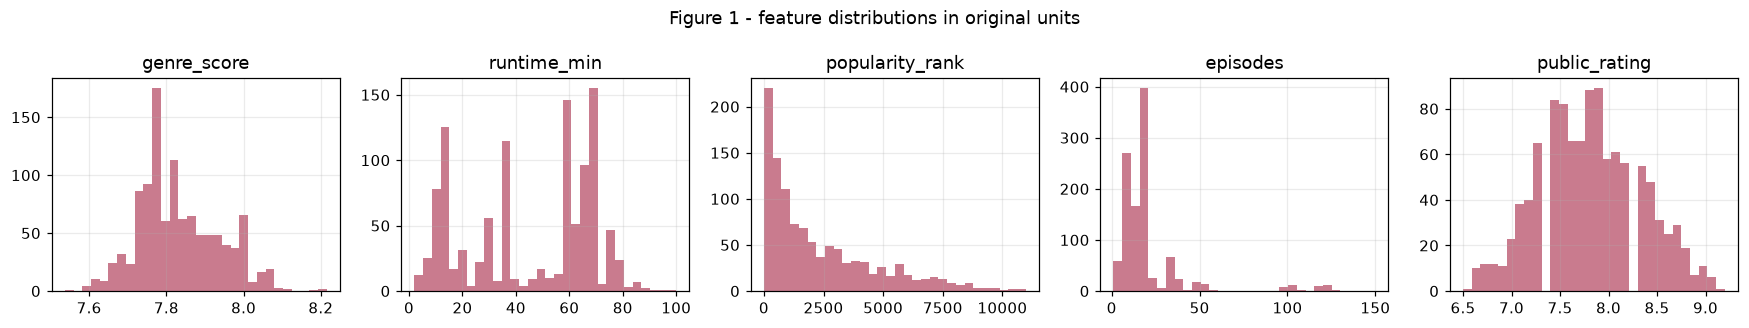

Skewness: {'genre_score': 0.45, 'runtime_min': -0.23, 'popularity_rank': 1.23, 'episodes': 3.4, 'public_rating': 0.13}


In [4]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3))
for ax, col in zip(axes, RAW_FEATURES):
    ax.hist(dramas[col], bins=30, color="#c97b8e"); ax.set_title(col)
fig.suptitle("Figure 1 - feature distributions in original units")
plt.tight_layout(); plt.show()
print("Skewness:", dramas[RAW_FEATURES].skew().round(2).to_dict())

**Figure 1 - three observations.** (1) `runtime_min` has **two peaks**: short web dramas (about 10-25 minutes) and standard TV dramas (about 60-70 minutes).
(2) `popularity_rank` and `episodes` are strongly right-skewed (skewness 1.2 and 3.4): a few dramas have 100+ episodes.
(3) `public_rating` and `genre_score` are roughly bell-shaped and narrow.

**Feature engineering.** Distance-based methods are dominated by extreme values, so we use `log10` for the two skewed columns:
`popularity_log` and `episodes_log` (skewness after the transformation: -1.0 and 0.6).

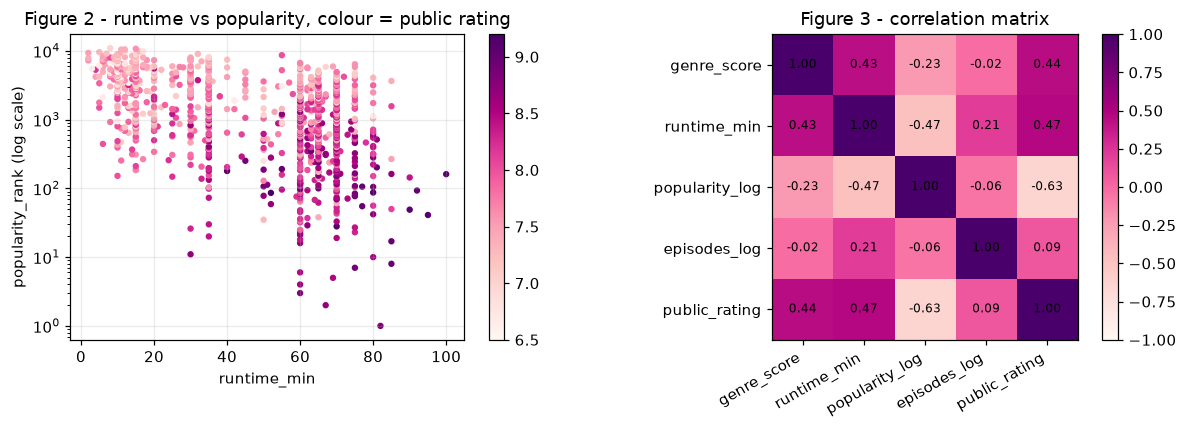

In [5]:
dramas["popularity_log"] = np.log10(dramas["popularity_rank"])
dramas["episodes_log"] = np.log10(dramas["episodes"])
FEATURES = ["genre_score", "runtime_min", "popularity_log", "episodes_log", "public_rating"]
X = dramas[FEATURES].copy()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sc = axes[0].scatter(dramas["runtime_min"], dramas["popularity_rank"], c=dramas["public_rating"], cmap="RdPu", s=10)
axes[0].set_yscale("log"); axes[0].set_xlabel("runtime_min"); axes[0].set_ylabel("popularity_rank (log scale)")
axes[0].set_title("Figure 2 - runtime vs popularity, colour = public rating")
fig.colorbar(sc, ax=axes[0])
corr = X.corr()
im = axes[1].imshow(corr, cmap="RdPu", vmin=-1, vmax=1)
axes[1].set_xticks(range(5), FEATURES, rotation=30, ha="right"); axes[1].set_yticks(range(5), FEATURES)
for i in range(5):
    for j in range(5):
        axes[1].text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
axes[1].grid(False); axes[1].set_title("Figure 3 - correlation matrix"); fig.colorbar(im, ax=axes[1])
plt.tight_layout(); plt.show()

**Figure 2.** Two vertical bands are visible (short and long episodes). Dark points (high rating) sit at the bottom: highly rated dramas are also the popular ones.
**Figure 3.** `public_rating` and `popularity_log` are clearly related (negative sign because rank 1 is the best). `episodes_log` is almost independent of the other features.
Correlated features mean that PCA should be able to compress the data.

## Step 4 - Standardize the features

K-Means, DBSCAN, PCA, t-SNE and UMAP all work with distances or variances. Without scaling, the feature with the largest numbers
(`runtime_min`, standard deviation about 24) would decide everything and `genre_score` (standard deviation about 0.1) would be ignored.
`StandardScaler` gives every feature mean 0 and standard deviation 1. This is exploratory analysis of one fixed table, so the scaler is fitted on all rows (there is no test set and no target).

In [6]:
X_imputed = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(X), columns=FEATURES)   # safe pattern; nothing is missing
scaler = StandardScaler()
Xs = scaler.fit_transform(X_imputed)
print("Means after scaling:", np.round(Xs.mean(axis=0), 3))
print("SDs after scaling:  ", np.round(Xs.std(axis=0), 3))

Means after scaling: [-0. -0.  0. -0.  0.]
SDs after scaling:   [1. 1. 1. 1. 1.]


### Step 4.1 - Data quality and scaling experiments

**Scaling experiment.** Same K and same seed, raw units versus standardized units.

**Imputation experiment.** Our table has no gaps, so to compare strategies we hide 5% of the `runtime_min` values **on purpose**
(this is an artificial test, clearly separated from the real analysis) and fill them with the mean or with the median.

In [7]:
K_TEST = 4
raw_labels = KMeans(n_clusters=K_TEST, n_init=10, random_state=SEED).fit_predict(X_imputed)
scaled_labels = KMeans(n_clusters=K_TEST, n_init=10, random_state=SEED).fit_predict(Xs)
print("Raw silhouette:   ", round(silhouette_score(X_imputed, raw_labels), 3))
print("Scaled silhouette:", round(silhouette_score(Xs, scaled_labels), 3))
print("Agreement between the two clusterings (ARI):", round(adjusted_rand_score(raw_labels, scaled_labels), 3))
print("Raw standard deviations:", X_imputed.std().round(3).to_dict())

rng = np.random.default_rng(SEED)
hidden = rng.choice(len(X), size=int(0.05 * len(X)), replace=False)
X_holes = X_imputed.copy()
X_holes.loc[hidden, "runtime_min"] = np.nan
for strategy in ["mean", "median"]:
    filled = SimpleImputer(strategy=strategy).fit_transform(X_holes)
    filled_scaled = StandardScaler().fit_transform(filled)
    labels = KMeans(n_clusters=K_TEST, n_init=10, random_state=SEED).fit_predict(filled_scaled)
    print(f"{strategy:6s} imputation of {len(hidden)} hidden values -> silhouette",
          round(silhouette_score(filled_scaled, labels), 3),
          "| ARI vs complete data", round(adjusted_rand_score(scaled_labels, labels), 3))

Raw silhouette:    0.661
Scaled silhouette: 0.285
Agreement between the two clusterings (ARI): 0.393
Raw standard deviations: {'genre_score': 0.105, 'runtime_min': 23.956, 'popularity_log': 0.639, 'episodes_log': 0.309, 'public_rating': 0.522}


mean   imputation of 54 hidden values -> silhouette 0.275 | ARI vs complete data 0.987


median imputation of 54 hidden values -> silhouette 0.276 | ARI vs complete data 0.929


**What the result means.**

* Raw data gives a *higher* silhouette (0.661) than scaled data (0.285). This does **not** mean raw is better:
  in raw units the clustering looks almost only at `runtime_min`, which has two clear peaks, so the groups are easy to separate but ignore the other features.
  The two clusterings agree only moderately (ARI = 0.39). We keep the standardized version because we want all five features to matter.
* Imputation: with 5% hidden values, mean imputation keeps the clusters almost unchanged (ARI = 0.99) and median imputation changes them a little more
  (ARI = 0.93). Reason: `runtime_min` has two peaks, and the median (55 min) puts every filled drama into the "long" group,
  while the mean (45 min) puts them between the groups. Neither is "true"; with two peaks a single fill value is always a compromise.

## Step 5 and 6 - K-Means: choose K with the elbow and silhouette methods

K-Means repeats two steps: (1) give every drama to the nearest centre (centroid); (2) move each centroid to the mean of its dramas.
We must choose K ourselves. **Inertia** (within-cluster squared distance) always goes down when K grows, so we look for an "elbow".
The **silhouette score** (from -1 to 1) compares how close a point is to its own cluster and to the nearest other cluster; higher is better.

,K,inertia,silhouette,smallest cluster
0,2,3647.990,0.302,517
1,3,2893.930,0.283,320
2,4,2427.097,0.285,125
3,5,2118.820,0.271,105
4,6,1907.186,0.267,92
5,7,1758.034,0.259,87
6,8,1641.218,0.239,78


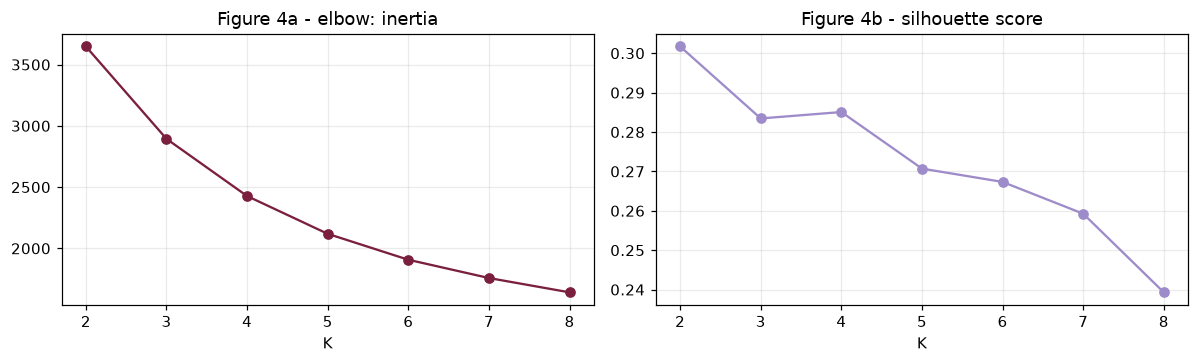

In [8]:
ks = list(range(2, 9))
inertias, silhouettes, smallest = [], [], []
for k in ks:
    model = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    labels = model.fit_predict(Xs)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(Xs, labels))
    smallest.append(np.bincount(labels).min())

display(pd.DataFrame({"K": ks, "inertia": inertias, "silhouette": silhouettes, "smallest cluster": smallest}).round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(ks, inertias, marker="o", color="#7a1f3d"); axes[0].set_title("Figure 4a - elbow: inertia"); axes[0].set_xlabel("K")
axes[1].plot(ks, silhouettes, marker="o", color="#9d8cc9"); axes[1].set_title("Figure 4b - silhouette score"); axes[1].set_xlabel("K")
plt.tight_layout(); plt.show()

**Choosing K - honest reading of the evidence.**

* The elbow curve is smooth: there is no sharp corner. The biggest drops are from K=2 to K=3 and from K=3 to K=4; after K=4 the gains become smaller.
* The silhouette is highest at **K=2 (0.302)**: the strongest structure in the data is simply "short web dramas" versus "full-length dramas".
  For K=3 it is 0.283, for **K=4 it is 0.285** (a small second peak), and then it falls (0.271 at K=5).
* **We choose K = 4.** K=2 is statistically the cleanest answer, but it only repeats what the runtime histogram already showed. K=4 costs very little silhouette
  (0.302 -> 0.285), sits where the elbow curve flattens, and gives four groups that are easy to describe.
  All silhouette values are low (about 0.3), so the groups **overlap**: they are useful segments, not sharply separated natural classes.

In [9]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEED)
km_labels = kmeans.fit_predict(Xs)
print("Cluster sizes:", pd.Series(km_labels).value_counts().sort_index().to_dict())
print("Inertia:", round(kmeans.inertia_, 1), "| silhouette:", round(silhouette_score(Xs, km_labels), 3))

Cluster sizes: {0: 125, 1: 337, 2: 280, 3: 352}
Inertia: 2427.1 | silhouette: 0.285


### Task 6.1 - K-Means stability and cluster profiles

A centroid is just the arithmetic mean of the points in a cluster (first line below). K-Means starts from random centres, so we repeat it with five seeds.
Cluster numbers are arbitrary names, so we compare runs with the Adjusted Rand Index (ARI: 1 = identical grouping), not by the numbers.
Profiles are shown in the **original units**.

Manual centroid of the first three dramas (genre_score, runtime_min): [ 7.83  69.667]


,seed,inertia,silhouette,ARI vs seed 42
0,0,2426.947,0.285,0.943
1,1,2427.097,0.285,1.000
2,2,2428.858,0.284,0.890
3,3,2427.157,0.285,0.992
4,4,2427.109,0.285,0.995


,size,genre_score,runtime_min,popularity_rank,episodes,public_rating,year,median popularity_rank
cluster,,,,,,,,
0,125,7.76,41.04,3819.49,66.62,7.54,2017.93,3527.0
1,337,7.76,15.86,3884.55,9.64,7.47,2018.89,3634.0
2,280,7.89,63.12,311.02,16.74,8.43,2019.24,216.0
3,352,7.88,60.72,1871.96,16.23,7.73,2018.98,1544.0


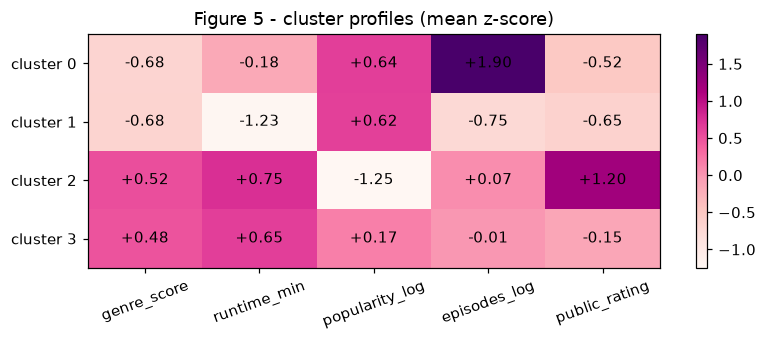

cluster 0: top genres {'Romance': 0.9, 'Drama': 0.68, 'Melodrama': 0.54, 'Comedy': 0.42}
           most popular examples: ['Tempted', 'Where Stars Land', 'Love with Flaws', 'Wok of Love', 'Temperature of Love']
cluster 1: top genres {'Romance': 0.83, 'Drama': 0.49, 'Comedy': 0.45, 'Youth': 0.43}
           most popular examples: ['Where Your Eyes Linger', 'Color Rush', 'EXO Next Door', 'To My Star', 'Mr. Heart']
cluster 2: top genres {'Romance': 0.62, 'Drama': 0.58, 'Comedy': 0.39, 'Mystery': 0.33}
           most popular examples: ['Goblin', 'Strong Woman Do Bong Soon', 'Weightlifting Fairy Kim Bok Joo', 'Descendants of the Sun', "What's Wrong with Secretary Kim"]
cluster 3: top genres {'Drama': 0.57, 'Romance': 0.53, 'Comedy': 0.43, 'Mystery': 0.39}
           most popular examples: ['Nevertheless,', 'Melting Me Softly', 'Record of Youth', 'Blood', 'Radio Romance']


In [10]:
points = X_imputed.iloc[:3, :2].to_numpy()
print("Manual centroid of the first three dramas (genre_score, runtime_min):", points.mean(axis=0).round(3))

rows = []
for seed in range(5):
    m = KMeans(n_clusters=K, n_init=10, random_state=seed)
    lab = m.fit_predict(Xs)
    rows.append({"seed": seed, "inertia": m.inertia_, "silhouette": silhouette_score(Xs, lab),
                 "ARI vs seed 42": adjusted_rand_score(km_labels, lab)})
display(pd.DataFrame(rows).round(3))

profile_cols = ["genre_score", "runtime_min", "popularity_rank", "episodes", "public_rating", "year"]
profiles = dramas.assign(cluster=km_labels).groupby("cluster")[profile_cols].mean().round(2)
profiles.insert(0, "size", pd.Series(km_labels).value_counts().sort_index())
profiles["median popularity_rank"] = dramas.assign(cluster=km_labels).groupby("cluster")["popularity_rank"].median()
display(profiles)

z_means = pd.DataFrame(Xs, columns=FEATURES).assign(cluster=km_labels).groupby("cluster").mean()
fig, ax = plt.subplots(figsize=(7.5, 3.2))
im = ax.imshow(z_means.values, cmap="RdPu", aspect="auto")
ax.set_xticks(range(5), FEATURES, rotation=20); ax.set_yticks(range(K), [f"cluster {c}" for c in range(K)])
for i in range(K):
    for j in range(5):
        ax.text(j, i, f"{z_means.values[i, j]:+.2f}", ha="center", va="center")
ax.grid(False); ax.set_title("Figure 5 - cluster profiles (mean z-score)"); fig.colorbar(im)
plt.tight_layout(); plt.show()

for c in range(K):
    members = dramas[km_labels == c]
    top_genres = (members["genres"].str.split("|").explode().value_counts() / len(members)).head(4).round(2).to_dict()
    print(f"cluster {c}: top genres {top_genres}")
    print("           most popular examples:", members.sort_values("popularity_rank")["title"].head(5).tolist())

**What the result means.**

* **Stability:** five different seeds give almost the same inertia and silhouette, and the groupings agree strongly
  (ARI between 0.89 and 1.00). The solution does not depend much on the random start.
* **Cluster profiles** (means in original units; the description is generated from the z-scores, not invented):

| Cluster | Size | Runtime (min) | Episodes | Median popularity rank | Public rating | Genre score | Data-derived description |
|---|---|---|---|---|---|---|---|
| 0 | 125 (11%) | 41 | 67 | 3527 | 7.54 | 7.76 | more episodes, lower genre score, less popular, lower public rating |
| 1 | 337 (31%) | 16 | 10 | 3634 | 7.47 | 7.76 | shorter episodes, fewer episodes, lower genre score, lower public rating, less popular |
| 2 | 280 (26%) | 63 | 17 | 216 | 8.43 | 7.89 | more popular, higher public rating, longer episodes, higher genre score |
| 3 | 352 (32%) | 61 | 16 | 1544 | 7.73 | 7.88 | longer episodes |

* In plain words: one group is **short web dramas**, one is **long-running serials** with many episodes, one is the **popular, highly rated hits**, and one is the
  **standard-format dramas with average popularity**. These names are our reading of the numbers; the algorithm only returns the numbers 0-3.
* Genres were **not** used for clustering (only the numeric genre score), so the top-genre lists are an external description. Romance, Drama and Comedy lead in every cluster, which shows that these groups are about *format and popularity*, not about genre.

## Step 7 - DBSCAN density clustering

DBSCAN does not need K. A point is a **core point** if at least `min_samples` points lie within distance `eps`. Connected core points form a cluster;
points that belong to no dense region get the label **-1 (noise)**. To choose `eps` we use the k-distance plot: the distance from each drama to its 10th nearest neighbour.
A common rule of thumb is `min_samples = 2 x number of features = 10`.

k-distance percentiles (50, 75, 90, 95, 99): [0.73 0.93 1.2  1.39 1.71]
-1    205
 0    478
 1     79
 2    292
 3     40
Clusters: 4 | noise points: 205


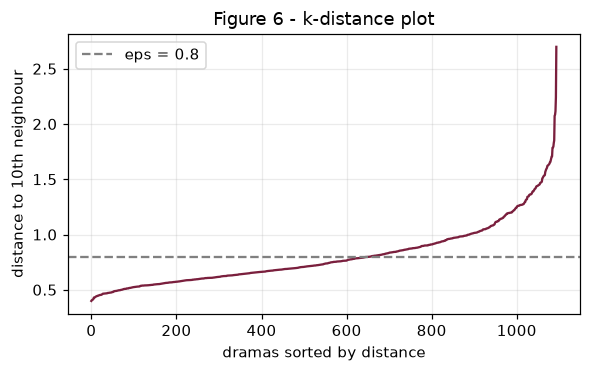

In [11]:
MIN_SAMPLES = 10
k_distance = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Xs).kneighbors(Xs)[0][:, -1])
print("k-distance percentiles (50, 75, 90, 95, 99):", np.percentile(k_distance, [50, 75, 90, 95, 99]).round(2))

EPS = 0.8
db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES)
db_labels = db.fit_predict(Xs)
print(pd.Series(db_labels).value_counts().sort_index().to_string())
print("Clusters:", len(set(db_labels) - {-1}), "| noise points:", int((db_labels == -1).sum()))

plt.figure(figsize=(6, 3.3))
plt.plot(k_distance, color="#7a1f3d"); plt.axhline(EPS, color="gray", linestyle="--", label=f"eps = {EPS}")
plt.xlabel("dramas sorted by distance"); plt.ylabel("distance to 10th neighbour")
plt.title("Figure 6 - k-distance plot"); plt.legend(); plt.show()

### Step 7.1 - DBSCAN sensitivity (15 settings)

We try every combination of five `eps` values and three `min_samples` values. Silhouette is computed **without the noise points**
and only when there are at least two clusters (otherwise it is not defined).

,eps,min_samples,clusters,noise,noise share,silhouette (no noise)
0,0.5,5,15,563,0.515,0.025
1,0.5,10,5,852,0.779,0.425
2,0.5,15,2,1032,0.943,0.775
3,0.6,5,11,332,0.303,0.049
4,0.6,10,7,560,0.512,0.271
5,0.6,15,3,747,0.683,0.600
6,0.7,5,6,209,0.191,0.108
7,0.7,10,7,322,0.294,0.231
8,0.7,15,4,464,0.424,0.335
9,0.8,5,5,125,0.114,0.016


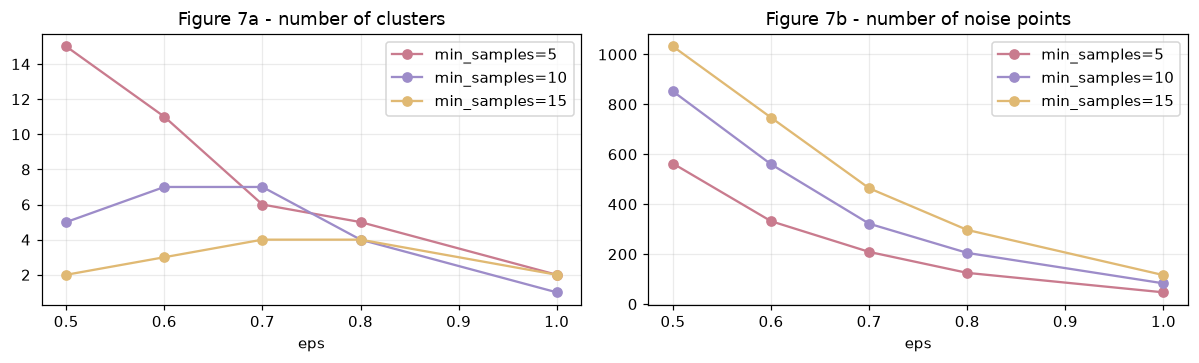

K-Means cluster (rows) vs DBSCAN cluster (columns, -1 = noise):


dbscan,-1,0,1,2,3
kmeans,,,,,
0,46,0,39,0,40
1,45,1,1,290,0
2,68,199,12,1,0
3,46,278,27,1,0


ARI between K-Means and DBSCAN on non-noise dramas: 0.61


,runtime_min,episodes,popularity_rank,public_rating,genre_score
dbscan,,,,,
-1,47.94,22.32,2153.01,7.88,7.84
0,65.58,15.24,1194.80,8.01,7.88
1,33.23,33.92,1627.15,7.86,7.86
2,14.98,9.97,3990.46,7.46,7.76
3,33.85,113.05,5657.62,7.42,7.74


In [12]:
rows = []
for eps in [0.5, 0.6, 0.7, 0.8, 1.0]:
    for ms in [5, 10, 15]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(Xs)
        groups = len(set(lab) - {-1})
        noise = int((lab == -1).sum())
        keep = lab != -1
        sil = silhouette_score(Xs[keep], lab[keep]) if groups >= 2 else np.nan
        rows.append((eps, ms, groups, noise, round(noise / len(lab), 3), sil))
grid = pd.DataFrame(rows, columns=["eps", "min_samples", "clusters", "noise", "noise share", "silhouette (no noise)"])
display(grid.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ms, color in zip([5, 10, 15], PALETTE):
    part = grid[grid["min_samples"] == ms]
    axes[0].plot(part["eps"], part["clusters"], marker="o", color=color, label=f"min_samples={ms}")
    axes[1].plot(part["eps"], part["noise"], marker="o", color=color, label=f"min_samples={ms}")
axes[0].set_title("Figure 7a - number of clusters"); axes[1].set_title("Figure 7b - number of noise points")
for ax in axes:
    ax.set_xlabel("eps"); ax.legend()
plt.tight_layout(); plt.show()

print("K-Means cluster (rows) vs DBSCAN cluster (columns, -1 = noise):")
display(pd.crosstab(pd.Series(km_labels, name="kmeans"), pd.Series(db_labels, name="dbscan")))
keep = db_labels != -1
print("ARI between K-Means and DBSCAN on non-noise dramas:", round(adjusted_rand_score(km_labels[keep], db_labels[keep]), 3))
display(dramas.assign(dbscan=db_labels).groupby("dbscan")[["runtime_min", "episodes", "popularity_rank", "public_rating", "genre_score"]].mean().round(2))

**What the result means.**

* **Main setting** `eps = 0.8`, `min_samples = 10`: **4 clusters and 205 noise points** (19% of the dramas).
  The k-distance curve bends between the 75th percentile (0.93) and the 95th percentile (1.39), so 0.8 is a reasonable radius.
* **Sensitivity is high.** With `eps = 0.5, min_samples = 5` DBSCAN finds 15 small clusters and 563 noise points;
  with `eps = 1.0, min_samples = 10` it finds 1 cluster and only 83 noise points. Small eps = many tiny groups and a lot of noise; large eps = everything merges.
  There is no single "correct" setting - the density of this dataset changes smoothly.
* **DBSCAN vs K-Means.** DBSCAN separates the short web dramas and the long serials clearly (they are dense and far from the rest), but it puts the K-Means "hits" and "standard" groups into **one** big cluster,
  because there is no empty space between them. On the dramas that DBSCAN does not call noise, the two methods agree moderately (ARI = 0.61).
  K-Means must give every drama a cluster; DBSCAN is allowed to say "this one does not belong anywhere".
* **Noise is not an error.** A noise point is only a drama in a sparse region for this eps and min_samples.

## Step 8 - PCA and explained variance

PCA finds new axes (principal components) that are straight-line mixtures of the standardized features.
PC1 keeps as much variance as possible, PC2 keeps as much as possible of the rest, and so on. It is linear and deterministic.

Explained variance ratio: [0.475 0.206 0.158 0.101 0.06 ]
Cumulative variance:      [0.475 0.681 0.839 0.94  1.   ]


,genre_score,runtime_min,popularity_log,episodes_log,public_rating
PC1,0.42,0.51,-0.50,0.13,0.55
PC2,-0.29,0.15,0.04,0.94,-0.10


Total retained by 2 components: 0.681


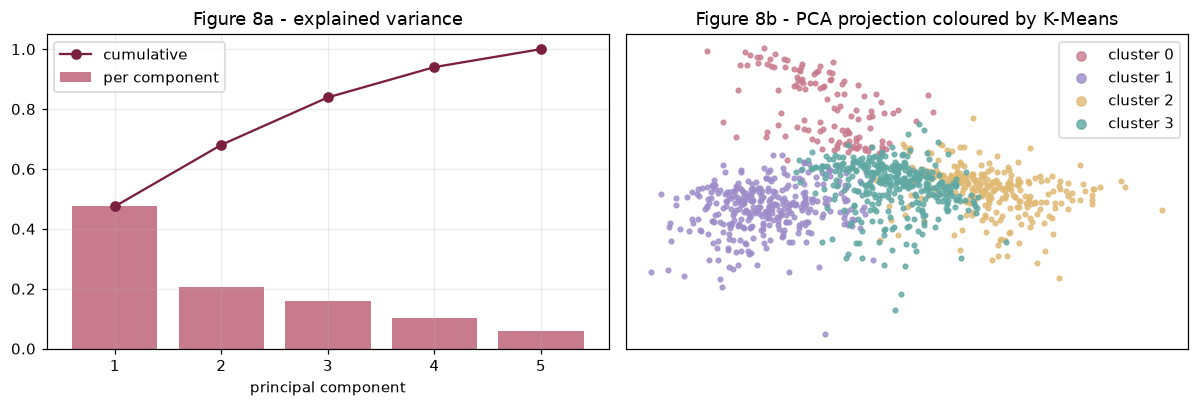

In [13]:
pca_full = PCA().fit(Xs)
ratio = pca_full.explained_variance_ratio_
print("Explained variance ratio:", ratio.round(3))
print("Cumulative variance:     ", np.cumsum(ratio).round(3))
loadings = pd.DataFrame(pca_full.components_[:2], columns=FEATURES, index=["PC1", "PC2"])
display(loadings.round(2))

pca = PCA(n_components=2)
Xp = pca.fit_transform(Xs)
print("Total retained by 2 components:", round(pca.explained_variance_ratio_.sum(), 3))

def scatter(ax, xy, labels, title, noise_label=None):
    for c in sorted(set(labels)):
        mask = labels == c
        if c == noise_label:
            ax.scatter(xy[mask, 0], xy[mask, 1], s=9, c="#3a3942", marker="x", label="noise", alpha=0.7)
        else:
            ax.scatter(xy[mask, 0], xy[mask, 1], s=9, c=PALETTE[c % len(PALETTE)], label=f"cluster {c}", alpha=0.8)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(range(1, 6), ratio, color="#c97b8e", label="per component")
axes[0].plot(range(1, 6), np.cumsum(ratio), marker="o", color="#7a1f3d", label="cumulative")
axes[0].set_xlabel("principal component"); axes[0].set_title("Figure 8a - explained variance"); axes[0].legend()
scatter(axes[1], Xp, km_labels, "Figure 8b - PCA projection coloured by K-Means"); axes[1].legend(markerscale=2)
plt.tight_layout(); plt.show()

**What the result means.**

* PC1 keeps **47.5%** and PC2 keeps **20.6%** of the standardized variance: **68.1% in two dimensions**.
  About 32% of the information is not visible in the 2-D picture; three components would keep 83.9%.
* **Loadings.** PC1 mixes `public_rating`, `runtime_min`, `genre_score` (positive) and `popularity_log` (negative): it is a "mainstream success" axis - long, well-rated, popular dramas on one side, short and less-known ones on the other.
  PC2 is almost only `episodes_log` (0.94): the "number of episodes" axis. Loadings describe directions of variance, not causes.
* In the scatter plot the K-Means groups are visible as regions but they **touch and overlap**. Overlap in 2-D does not prove overlap in all five dimensions.

## Step 9 - t-SNE visualization

t-SNE is a non-linear method. It tries to keep **neighbours** together: dramas that are close in five dimensions should be close on the map.
It does not keep global distances: the size of a blob and the space between blobs have no direct meaning.
Colours are the K-Means labels - they are added for reading only; t-SNE itself never sees them.

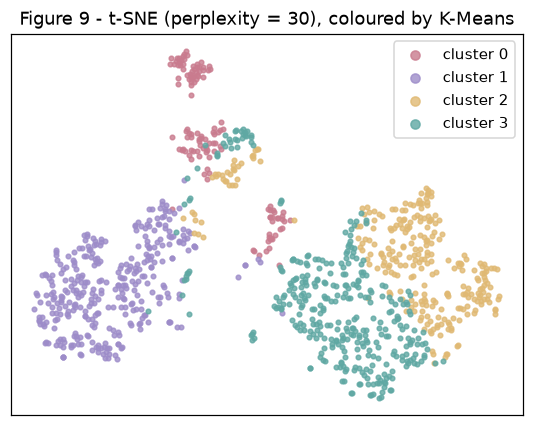

In [14]:
tsne = TSNE(n_components=2, perplexity=30, random_state=SEED, init="pca", learning_rate="auto")
Xt = tsne.fit_transform(Xs)
fig, ax = plt.subplots(figsize=(6, 4.5))
scatter(ax, Xt, km_labels, "Figure 9 - t-SNE (perplexity = 30), coloured by K-Means"); ax.legend(markerscale=2)
plt.show()

**What the result means.** t-SNE draws several islands. The short web dramas and the long serials form their own islands, which agrees with K-Means and DBSCAN.
But the islands are a *visualization*: t-SNE tends to cut continuous data into separate blobs, so a gap on this map is **not proof** of a real cluster.
We trust a group only when several methods agree.

## Step 10 - UMAP visualization

UMAP is another non-linear method. It builds a graph of nearest neighbours and then draws that graph in 2-D.
`n_neighbors` balances local detail and the bigger picture; `min_dist` controls how tightly points are packed.

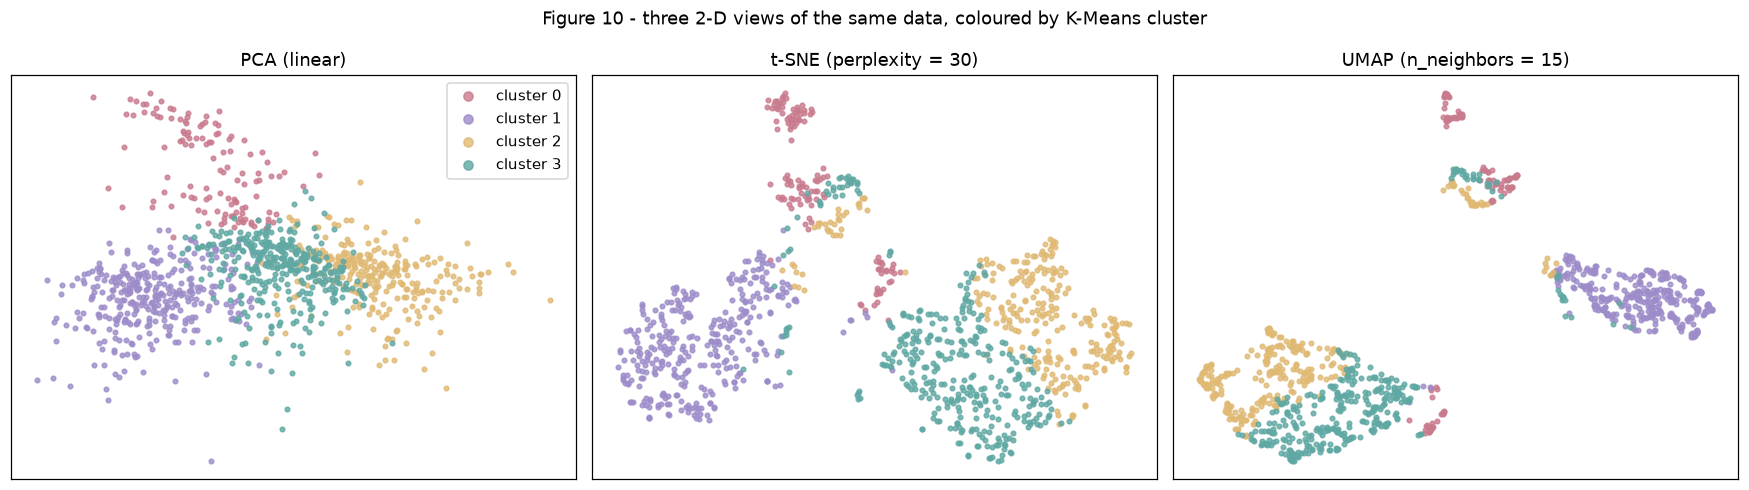

In [15]:
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=SEED)
Xu = reducer.fit_transform(Xs)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
scatter(axes[0], Xp, km_labels, "PCA (linear)")
scatter(axes[1], Xt, km_labels, "t-SNE (perplexity = 30)")
scatter(axes[2], Xu, km_labels, "UMAP (n_neighbors = 15)")
axes[0].legend(markerscale=2)
fig.suptitle("Figure 10 - three 2-D views of the same data, coloured by K-Means cluster")
plt.tight_layout(); plt.show()

**Comparing PCA, t-SNE and UMAP.**

| | PCA | t-SNE | UMAP |
|---|---|---|---|
| Type | linear | non-linear | non-linear |
| Keeps | global variance directions | local neighbourhoods | local neighbourhoods, some global layout |
| Axes have a meaning? | yes (loadings) | no | no |
| Same result every run? | yes | only with a fixed seed | only with a fixed seed |
| In our data | one continuous cloud, 68% of variance | several separate islands | compact, well separated islands |

All three agree on the main story: short web dramas and long serials stand apart, while "hits" and "standard" dramas are neighbours that blend into each other.
**PCA is the most interpretable** (its axes can be explained and its distances are honest), but it shows less separation.
t-SNE and UMAP look more "clustered", but that look is partly created by the method: distances between islands and island sizes must not be interpreted.

### Step 10.1 - Projection sensitivity

We change one setting of each method. If the picture changes a lot, we should not over-interpret any single picture.

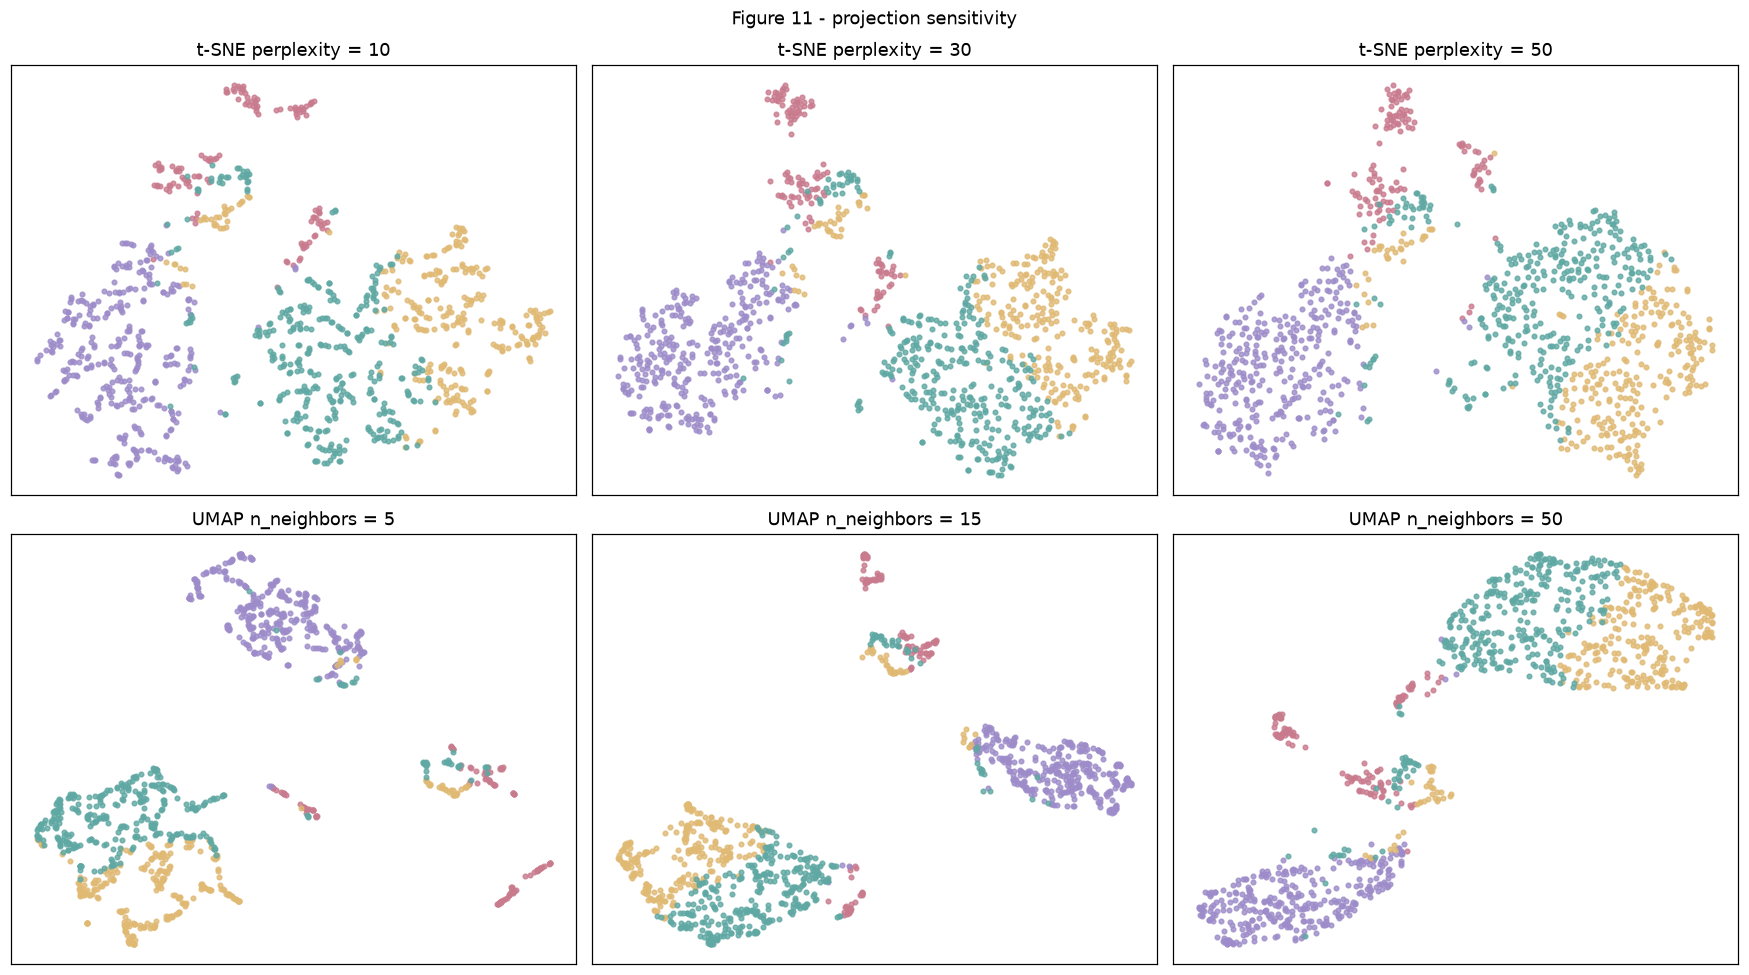

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, perplexity in zip(axes[0], [10, 30, 50]):
    z = Xt if perplexity == 30 else TSNE(n_components=2, perplexity=perplexity, random_state=SEED,
                                         init="pca", learning_rate="auto").fit_transform(Xs)
    scatter(ax, z, km_labels, f"t-SNE perplexity = {perplexity}")
for ax, n_neighbors in zip(axes[1], [5, 15, 50]):
    z = Xu if n_neighbors == 15 else umap.UMAP(n_neighbors=n_neighbors, min_dist=0.1, random_state=SEED).fit_transform(Xs)
    scatter(ax, z, km_labels, f"UMAP n_neighbors = {n_neighbors}")
fig.suptitle("Figure 11 - projection sensitivity")
plt.tight_layout(); plt.show()

**What the result means.** With a small perplexity or few neighbours the maps break into many small pieces; with large values the pieces merge into bigger shapes.
The *number* of islands therefore depends on the setting. What stays stable is which dramas are neighbours (the colours stay together). Absolute positions and distances cannot be compared between plots.

## Step 11 - Isolation Forest anomaly detection

Isolation Forest builds many random trees. Each tree cuts the data with random splits. An unusual drama is separated from the others after only a few cuts,
so it gets a low score. `contamination` is **our** decision about what share of dramas to flag - it is not a measured anomaly rate.

In [17]:
iso = IsolationForest(contamination=0.05, random_state=SEED)
outlier_labels = iso.fit_predict(Xs)                 # +1 = normal, -1 = flagged
anomaly_score = iso.decision_function(Xs)            # lower = more unusual
print(pd.Series(outlier_labels).value_counts().to_string())

top = dramas.assign(anomaly_score=anomaly_score, dbscan_noise=(db_labels == -1)).sort_values("anomaly_score").head(10)
display(top[["title", "year", "genres", "runtime_min", "episodes", "popularity_rank", "public_rating", "anomaly_score", "dbscan_noise"]].round(3))

 1    1039
-1      55


,title,year,genres,runtime_min,episodes,popularity_rank,public_rating,anomaly_score,dbscan_noise
7,Crash Landing on You,2019,Military|Comedy|Romance|Political,85.0,16.0,8.0,9.0,-0.107,True
0,Goblin,2016,Comedy|Romance|Fantasy|Melodrama,82.0,16.0,1.0,8.8,-0.089,True
1036,A Good Supper,2021,Romance|Drama|Family,30.0,120.0,7223.0,6.6,-0.083,True
11,Vincenzo,2021,Comedy|Law|Crime|Drama,85.0,20.0,17.0,9.0,-0.076,True
32,Reply 1988,2015,Comedy|Romance|Life|Youth,95.0,20.0,41.0,9.1,-0.074,True
134,D.P.,2021,Action|Military|Drama,50.0,6.0,187.0,8.8,-0.073,True
957,Boys Dormitory,2017,Romance|Youth,3.0,2.0,5514.0,6.7,-0.070,True
80,Mr. Sunshine,2018,Military|Historical|Romance|Melodrama,80.0,24.0,105.0,8.9,-0.060,True
39,Hospital Playlist,2020,Romance|Life|Drama|Medical,90.0,12.0,49.0,9.1,-0.059,True
999,Person Who Gives Happiness,2016,Romance|Family,35.0,118.0,6106.0,7.7,-0.056,True


### Step 11.1 - Contamination values and comparison with DBSCAN noise

,contamination,flagged,also DBSCAN noise (overlap),only Isolation Forest,only DBSCAN noise,disagreement
0,0.02,22,21,1,184,185
1,0.05,55,43,12,162,174
2,0.10,110,89,21,116,137


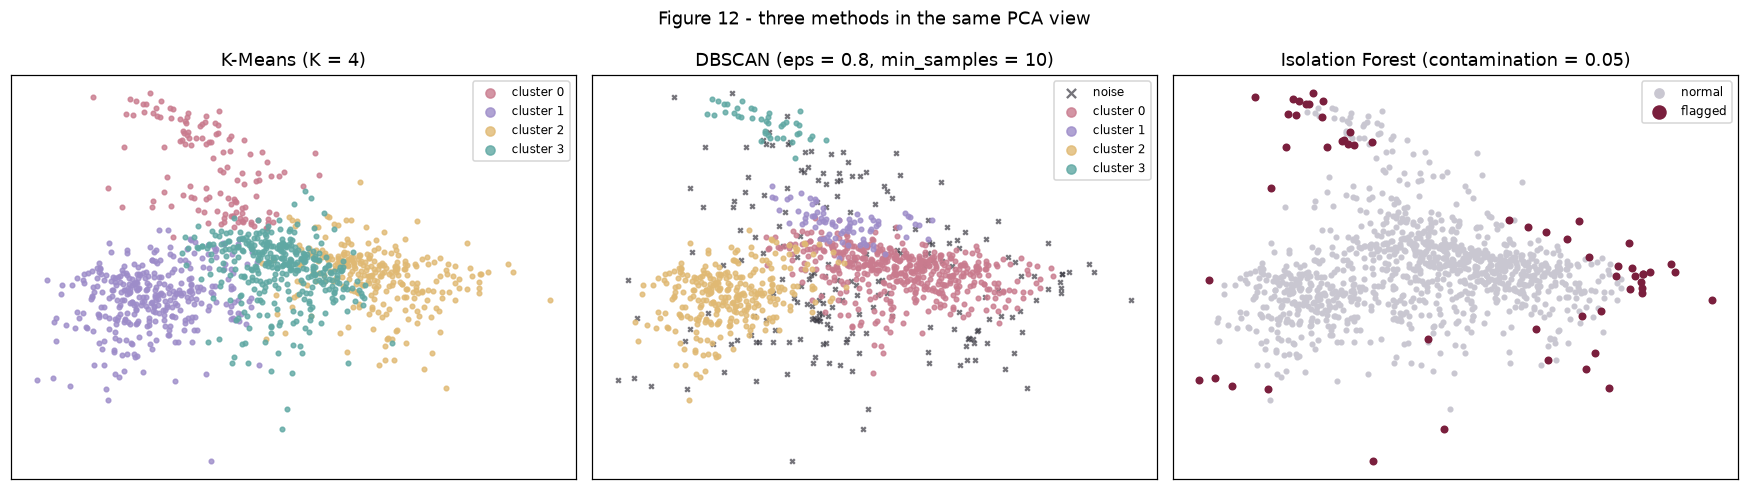

In [18]:
noise_mask = db_labels == -1
flags, rows = {}, []
for c in [0.02, 0.05, 0.10]:
    m = IsolationForest(contamination=c, random_state=SEED).fit(Xs)
    flags[c] = m.predict(Xs) == -1
    rows.append({"contamination": c, "flagged": int(flags[c].sum()),
                 "also DBSCAN noise (overlap)": int((noise_mask & flags[c]).sum()),
                 "only Isolation Forest": int((flags[c] & ~noise_mask).sum()),
                 "only DBSCAN noise": int((~flags[c] & noise_mask).sum()),
                 "disagreement": int((noise_mask != flags[c]).sum())})
display(pd.DataFrame(rows))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
scatter(axes[0], Xp, km_labels, "K-Means (K = 4)")
scatter(axes[1], Xp, db_labels, "DBSCAN (eps = 0.8, min_samples = 10)", noise_label=-1)
axes[2].scatter(Xp[~flags[0.05], 0], Xp[~flags[0.05], 1], s=9, c="#c9c7d1", label="normal")
axes[2].scatter(Xp[flags[0.05], 0], Xp[flags[0.05], 1], s=18, c="#7a1f3d", label="flagged")
axes[2].set_title("Isolation Forest (contamination = 0.05)"); axes[2].set_xticks([]); axes[2].set_yticks([]); axes[2].grid(False)
for ax in axes:
    ax.legend(markerscale=2, fontsize=8)
fig.suptitle("Figure 12 - three methods in the same PCA view")
plt.tight_layout(); plt.show()

**What the result means.**

| contamination | flagged | also DBSCAN noise | only Isolation Forest | only DBSCAN noise |
|---|---|---|---|---|
| 0.02 | 22 | 21 | 1 | 184 |
| 0.05 | 55 | 43 | 12 | 162 |
| 0.1 | 110 | 89 | 21 | 116 |

* With contamination = 0.05 the forest flags **55 dramas**; **43 of them (78%) are also DBSCAN noise**.
  So the dramas that Isolation Forest finds most unusual are almost always in sparse regions too. The opposite is not true: DBSCAN marks 205 dramas as noise, far more than the forest flags, because its "noise" simply means "not in a dense area".
  The two methods measure different kinds of unusual.
* **Who is flagged?** The most unusual dramas include *Crash Landing on You*, *Goblin*, *A Good Supper*, *Vincenzo*, *Reply 1988*. They are of two kinds: (a) **mega-hits** - extremely popular, very highly rated, long episodes;
  (b) **extreme formats** - daily serials with 100+ episodes or tiny web dramas of a few minutes. "Anomaly" here means *rare combination of values*, not *bad drama* and not *data error*.
* **Two checks before calling something a real anomaly:** (1) open the drama's page on MyDramaList and confirm that the runtime and number of episodes are correct (not a data-entry mistake);
  (2) check whether the flag stays when the seed or the contamination value changes.

## Step 12 - Combine the methods in one summary table

In [19]:
summary = pd.DataFrame({
    "title": dramas["title"], "kmeans_cluster": km_labels, "dbscan_cluster": db_labels,
    "isolation_forest_flag": outlier_labels, "PC1": Xp[:, 0].round(3), "PC2": Xp[:, 1].round(3),
})
display(summary.head(10))
print(summary.groupby("kmeans_cluster").size().to_string())
display(pd.crosstab(summary["kmeans_cluster"], summary["isolation_forest_flag"]).rename(columns={-1: "flagged", 1: "normal"}))

,title,kmeans_cluster,dbscan_cluster,isolation_forest_flag,PC1,PC2
0,Goblin,2,-1,-1,4.025,0.108
1,Strong Woman Do Bong Soon,2,-1,-1,3.592,-0.108
2,Weightlifting Fairy Kim Bok Joo,2,-1,-1,3.557,-0.263
3,Descendants of the Sun,2,-1,-1,3.146,-0.145
4,What's Wrong with Secretary Kim,2,-1,-1,2.723,0.239
5,W,2,-1,1,2.935,-0.138
6,It's Okay to Not Be Okay,2,-1,-1,3.580,-0.090
7,Crash Landing on You,2,-1,-1,4.695,-0.634
8,Hotel del Luna,2,0,-1,3.179,0.058
9,While You Were Sleeping,2,-1,-1,2.368,0.605


kmeans_cluster
0    125
1    337
2    280
3    352


isolation_forest_flag,flagged,normal
kmeans_cluster,,
0,19,106
1,6,331
2,29,251
3,1,351


## Conclusions

We analyzed **1,094 Korean dramas** and **5 numerical features** (genre score, runtime, popularity, episodes, public rating) built from two public Kaggle datasets scraped from MyDramaList.
After checking data quality (no missing values in the joined table), log-transforming two skewed features and standardizing, **K-Means suggested K = 4**: the silhouette is highest at K = 2 (0.302),
but K = 4 (0.285) lies where the elbow curve flattens and gives four interpretable groups (short web dramas, long serials, popular hits, standard dramas).
**DBSCAN** with eps = 0.8 and min_samples = 10 identified **4 groups and 205 noise points**, and its result changed strongly with the parameters.
The **first two PCA components retained 68.1%** of the standardized variance. The **t-SNE and UMAP** plots showed separate islands for short web dramas and long serials, subject to projection limitations.
**Isolation Forest** flagged **55 unusual dramas** with contamination = 0.05; 43 of them were also DBSCAN noise.
None of the unsupervised outputs independently establishes a ground-truth class or a verified anomaly.

**Evidence-based findings**
1. The strongest structure is *format*: episode length splits K-Dramas into web dramas and full-length dramas. Every method shows it.
2. Popularity, public rating and runtime move together (PC1, 47% of variance). Number of episodes is a separate, independent direction (PC2).
3. "Hits" are the upper end of a continuous scale, not a separate island: DBSCAN merges them with ordinary dramas and the silhouette is low.
4. The most unusual dramas are the global mega-hits and the extreme formats.

**Limitations**
1. Only dramas present in both sources are included (1,094 of 1,752), so less-known dramas are under-represented.
2. Clusters overlap (silhouette about 0.3); K = 4 is a useful choice, not a discovered truth.
3. DBSCAN, t-SNE and UMAP depend strongly on their parameters; contamination is chosen by us.
4. `genre_score` is built from `public_rating`, so these two features are related by construction.
5. Popularity rank and ratings are a snapshot from 2023; Source B has no stated licence (classroom use only).

**Improvements.** Add more features (tags, network, cast popularity); encode genres directly (multi-hot) instead of one score; try a Gaussian Mixture Model or HDBSCAN, which handle overlapping and uneven densities better; check cluster stability with bootstrap samples.

**Reproducibility.** `SEED = 42` is used for K-Means, t-SNE, UMAP and Isolation Forest; DBSCAN and PCA are deterministic. Run all cells from top to bottom. Small numerical differences in t-SNE/UMAP pictures are possible between library versions.

### Answers to the worksheet questions
* **Why must a known target be excluded from clustering features?** Unsupervised learning should find structure without the answer. If the target were a feature, the groups would simply copy the label and we would learn nothing new.
* **How did scaling change the results?** Without scaling the clustering followed almost only `runtime_min` (silhouette 0.66 but only one feature used); with scaling all five features count (silhouette 0.29); the two groupings agree only moderately (ARI 0.39).
* **What supports the selected K?** The elbow curve flattens after K = 4, the silhouette has a small second peak at K = 4, the solution is stable over seeds, and the four profiles are interpretable.
* **How sensitive is DBSCAN?** Very: from 15 clusters / 563 noise points to 1 cluster / 83 noise points inside our grid.
* **How much variance does PCA keep, and what do t-SNE/UMAP not preserve?** 68.1% in two components. t-SNE and UMAP do not preserve global distances, cluster sizes or densities.
* **Where do DBSCAN noise and Isolation Forest agree?** 43 of the 55 flagged dramas are also noise; 162 noise points are not flagged by the forest.
* **Two limitations?** Overlapping clusters with low silhouette, and strong parameter sensitivity of DBSCAN/t-SNE/UMAP (plus the selection of dramas present in both sources).

### References
* Charuchinda, C. (2023). *Korean Drama from 2015-2023 with Actors & Reviews* [Data set]. Kaggle. CC0 Public Domain. https://www.kaggle.com/datasets/chanoncharuchinda/korean-drama-2015-23-actor-and-reviewmydramalist
* Rizki, N. (2023). *Top Korean Drama List (~1500)* [Data set]. Kaggle. https://www.kaggle.com/datasets/noorrizki/top-korean-drama-list-1500
* MyDramaList. https://mydramalist.com (original source of both datasets)
* Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825-2830.
* van der Maaten, L., & Hinton, G. (2008). Visualizing Data using t-SNE. *Journal of Machine Learning Research*, 9, 2579-2605.
* McInnes, L., Healy, J., & Melville, J. (2018). UMAP: Uniform Manifold Approximation and Projection for Dimension Reduction. arXiv:1802.03426.
* Liu, F. T., Ting, K. M., & Zhou, Z.-H. (2008). Isolation Forest. *2008 Eighth IEEE International Conference on Data Mining*, 413-422.
* Ester, M., Kriegel, H.-P., Sander, J., & Xu, X. (1996). A Density-Based Algorithm for Discovering Clusters in Large Spatial Databases with Noise. *KDD-96*, 226-231.

In [20]:
# Key numbers of this run, saved so that the report and the website can be checked against the notebook.
import json
check = {"observations": int(len(dramas)),
         "k_silhouette": {int(k): float(s) for k, s in zip(ks, silhouettes)},
         "kmeans_sizes": [int(v) for v in np.bincount(km_labels)],
         "dbscan_clusters": int(len(set(db_labels) - {-1})), "dbscan_noise": int(noise_mask.sum()),
         "pca_ratio": [float(v) for v in ratio],
         "iso_flagged": {str(c): int(f.sum()) for c, f in flags.items()},
         "iso_overlap_noise": {str(c): int((f & noise_mask).sum()) for c, f in flags.items()}}
with open("p2_notebook_results.json", "w") as f:
    json.dump(check, f, indent=2)
print(json.dumps(check, indent=2))

{
  "observations": 1094,
  "k_silhouette": {
    "2": 0.30171858208357816,
    "3": 0.2834438665557273,
    "4": 0.28507135075456186,
    "5": 0.27071174438111406,
    "6": 0.26732837688882743,
    "7": 0.259259997137486,
    "8": 0.23929789180309566
  },
  "kmeans_sizes": [
    125,
    337,
    280,
    352
  ],
  "dbscan_clusters": 4,
  "dbscan_noise": 205,
  "pca_ratio": [
    0.47493596854186293,
    0.20563690001312904,
    0.15831048637381068,
    0.10116546925726759,
    0.05995117581392969
  ],
  "iso_flagged": {
    "0.02": 22,
    "0.05": 55,
    "0.1": 110
  },
  "iso_overlap_noise": {
    "0.02": 21,
    "0.05": 43,
    "0.1": 89
  }
}
